# Integrated Syntactic–Semantic Analysis: Keyword Extraction and Sentiment

**Authors:** Steve and Spencer
**Topic 4:** Integrated Analysis (coding task)

## Goal

1. Use **dependency parsing** (syntax) to pull out keywords and phrases from social-media style posts.
2. Score the **sentiment** (semantics) of those phrases.
3. Show why combining the two beats scoring whole sentences on their own.

## Approach

| Step | Layer | Tool |
|---|---|---|
| Parse each post into a dependency tree | Syntax | spaCy `en_core_web_sm` |
| Extract aspect + opinion pairs from specific grammatical relations | Syntax | `amod`, `nsubj`+`acomp`/`attr`, `dobj`, `neg`, `advmod`, `conj` |
| Score the opinion word, then adjust for negation and intensifiers | Semantics | VADER lexicon |
| Aggregate by aspect (battery, camera, ...) | Both | pandas + matplotlib |

## 1. Setup

Run the next cell once if the libraries are not installed yet.

In [1]:
# Uncomment and run once if needed
# !pip install spacy vaderSentiment pandas matplotlib
# !python -m spacy download en_core_web_sm

In [2]:
import re
from collections import Counter, defaultdict

import pandas as pd
import matplotlib.pyplot as plt
import spacy
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

nlp = spacy.load("en_core_web_sm")
vader = SentimentIntensityAnalyzer()
pd.set_option("display.max_colwidth", 80)
print("spaCy", spacy.__version__, "| model:", nlp.meta["name"])

spaCy 3.8.18 | model: core_web_sm


## 2. Sample data

A small set of made-up posts about a fictional phone, written the way people post on social media. Replace this list with your own data (for example a CSV of tweets) to reuse the notebook.

The list deliberately includes tricky cases: negation, contrast ("but"), intensifiers, and one sarcastic post.

In [3]:
posts = [
    "The camera is amazing and the screen is gorgeous.",
    "The battery is not good, it dies before lunch.",
    "I love the fast charging but the price is ridiculous.",
    "Not bad at all, the speakers are really impressive.",
    "Terrible customer service, I waited two hours for a reply.",
    "The delivery was quick and the packaging was solid.",
    "This phone has a beautiful design and a smooth interface.",
    "The software update ruined the battery and made the phone slow.",
    "Honestly the camera is not great in low light.",
    "I hate the flimsy case that came with it.",
    "Great, another phone that overheats. Just what I needed.",   # sarcasm
    "Very disappointing battery life, but the display is excellent.",
    "The support team was helpful and friendly.",
    "The price is fair and the performance is fantastic.",
]
print(len(posts), "posts loaded")

14 posts loaded


## 3. Look at a dependency parse

Before extracting anything, it helps to see the tree for one sentence. Each token has a **dependency label** (`dep_`) and a **head** that it attaches to. These relations are what we will use as extraction rules.

In [4]:
doc = nlp("The battery is not good, it dies before lunch.")
pd.DataFrame(
    [(t.i, t.text, t.pos_, t.dep_, t.head.text) for t in doc],
    columns=["i", "token", "pos", "dep", "head"],
)

,i,token,pos,dep,head
0,0,The,DET,det,battery
1,1,battery,NOUN,nsubj,is
2,2,is,AUX,ccomp,dies
3,3,not,PART,neg,is
4,4,good,ADJ,acomp,is
5,5,",",PUNCT,punct,dies
6,6,it,PRON,nsubj,dies
7,7,dies,VERB,ROOT,dies
8,8,before,ADP,prep,dies
9,9,lunch,NOUN,pobj,before


In [5]:
from spacy import displacy
displacy.render(nlp("The battery is not good."), style="dep", jupyter=True, options={"distance": 90})

## 4. Syntactic extraction: aspects, opinions and phrases

We look for four grammatical patterns. Each one yields an **aspect** (the thing being talked about) and an **opinion** (what is said about it).

| Pattern | Dependency rule | Example |
|---|---|---|
| Adjective modifier | adjective with `amod` attached to a noun | *gorgeous screen* |
| Copular predicate | noun `nsubj` of a verb that has an `acomp` or `attr` child | *battery is good* |
| Verb + object | opinion verb with a `dobj` noun | *love the camera* |
| Coordination | `conj` words joined to an opinion word | *quick and solid* |

We also record **negation** (a `neg` child on the opinion word or on the verb it hangs from) and **intensifiers** (an `advmod` child such as *very* or *really*).

In [6]:
NOUNS = {"NOUN", "PROPN"}
INTENSIFIERS = {"very", "really", "extremely", "so", "incredibly", "absolutely", "super"}

def is_negated(opinion_tok, governor=None):
    """Negation can sit on the opinion word itself or on the verb it attaches to."""
    if any(c.dep_ == "neg" for c in opinion_tok.children):
        return True
    if governor is not None and any(c.dep_ == "neg" for c in governor.children):
        return True
    return False

def intensity(opinion_tok):
    return 1.3 if any(c.dep_ == "advmod" and c.lower_ in INTENSIFIERS for c in opinion_tok.children) else 1.0

def aspect_text(noun_tok):
    """Use the noun's lemma, plus a leading compound noun if there is one (customer service)."""
    comps = [c.lemma_.lower() for c in noun_tok.children if c.dep_ == "compound"]
    return " ".join(comps + [noun_tok.lemma_.lower()])

def extract_pairs(doc):
    pairs, seen = [], set()

    def add(aspect_tok, opinion_tok, rule, governor=None):
        key = (aspect_tok.i, opinion_tok.i)
        if key in seen:
            return
        seen.add(key)
        pairs.append({
            "aspect": aspect_text(aspect_tok),
            "opinion": opinion_tok.lower_,
            "negated": is_negated(opinion_tok, governor),
            "boost": intensity(opinion_tok),
            "rule": rule,
        })

    for tok in doc:
        # 1) amod: "gorgeous screen"
        if tok.dep_ == "amod" and tok.head.pos_ in NOUNS:
            add(tok.head, tok, "amod")
            for conj in tok.conjuncts:
                add(tok.head, conj, "amod+conj")

        # 2) copular: "the battery is (not) good"
        if tok.dep_ == "nsubj" and tok.pos_ in NOUNS:
            gov = tok.head
            for child in gov.children:
                if child.dep_ in ("acomp", "attr"):
                    add(tok, child, "nsubj+acomp", governor=gov)
                    for conj in child.conjuncts:
                        add(tok, conj, "nsubj+acomp+conj", governor=gov)

        # 3) verb + direct object: "love the camera", "ruined the battery"
        if tok.dep_ == "dobj" and tok.pos_ in NOUNS:
            verb = tok.head
            if verb.pos_ == "VERB":
                add(tok, verb, "verb+dobj")

    return pairs

for p in extract_pairs(nlp("The battery is not good, it dies before lunch.")):
    print(p)

{'aspect': 'battery', 'opinion': 'good', 'negated': True, 'boost': 1.0, 'rule': 'nsubj+acomp'}


### Keyword and phrase extraction

Alongside the aspect/opinion pairs we pull out **noun phrases** (`noun_chunks`) and **adjective + noun phrases**, dropping determiners and pronouns. These are the keywords we count.

In [7]:
def keyword_phrases(doc):
    phrases = []
    for chunk in doc.noun_chunks:
        toks = [t for t in chunk if t.pos_ not in ("DET", "PRON") and not t.is_stop]
        if toks:
            phrases.append(" ".join(t.lemma_.lower() for t in toks))
    return phrases

for text in posts[:4]:
    print(text)
    print("  ->", keyword_phrases(nlp(text)))

The camera is amazing and the screen is gorgeous.
  -> ['camera', 'screen']
The battery is not good, it dies before lunch.
  -> ['battery', 'lunch']
I love the fast charging but the price is ridiculous.
  -> ['fast charging', 'price']
Not bad at all, the speakers are really impressive.
  -> ['speaker']


## 5. Semantic step: sentiment of each opinion

The score for an opinion word comes from the VADER lexicon. Then the syntax-derived flags adjust it:

- **Negated:** flip the sign and shrink it a little (*not good* is mildly negative, not as strong as *terrible*).
- **Intensified:** multiply by 1.3 (*really impressive*).

Result is a value in roughly [-1, 1].

In [8]:
NEG_FACTOR = -0.75

def opinion_score(opinion, negated, boost):
    score = vader.polarity_scores(opinion)["compound"]
    score *= boost
    if negated:
        score *= NEG_FACTOR
    return max(-1.0, min(1.0, score))

def label(score, thr=0.05):
    return "positive" if score > thr else "negative" if score < -thr else "neutral"

for args in [("good", False, 1.0), ("good", True, 1.0), ("impressive", False, 1.3), ("terrible", False, 1.0)]:
    print(args, "->", round(opinion_score(*args), 3))

('good', False, 1.0) -> 0.44
('good', True, 1.0) -> -0.33
('impressive', False, 1.3) -> 0.664
('terrible', False, 1.0) -> -0.477


## 6. Run the pipeline on all posts

In [9]:
rows = []
for idx, text in enumerate(posts):
    doc = nlp(text)
    sent_level = vader.polarity_scores(text)["compound"]      # whole-sentence baseline
    for p in extract_pairs(doc):
        s = opinion_score(p["opinion"], p["negated"], p["boost"])
        rows.append({
            "post": idx,
            "aspect": p["aspect"],
            "opinion": ("not " if p["negated"] else "") + p["opinion"],
            "rule": p["rule"],
            "phrase_score": round(s, 3),
            "phrase_label": label(s),
            "sentence_score": round(sent_level, 3),
        })

df = pd.DataFrame(rows)
df

,post,aspect,opinion,rule,phrase_score,phrase_label,sentence_score
0,0,camera,amazing,nsubj+acomp,0.586,positive,0.832
1,0,screen,gorgeous,nsubj+acomp,0.612,positive,0.832
2,1,battery,not good,nsubj+acomp,-0.330,negative,-0.341
3,2,charging,fast,amod,0.000,neutral,-0.166
4,2,charging,love,verb+dobj,0.637,positive,-0.166
5,2,price,ridiculous,nsubj+acomp,-0.361,negative,-0.166
6,3,speaker,impressive,nsubj+acomp,0.664,positive,0.754
7,4,customer service,terrible,amod,-0.477,negative,-0.477
8,4,hour,waited,verb+dobj,0.000,neutral,-0.477
9,5,delivery,quick,nsubj+acomp,0.000,neutral,0.153


## 7. Results

### 7.1 Sentiment per aspect

Averaging phrase scores by aspect gives the kind of feature-level view a company would want from social media.

In [10]:
agg = (df.groupby("aspect")
         .agg(mentions=("phrase_score", "size"), mean_sentiment=("phrase_score", "mean"))
         .sort_values("mean_sentiment"))
agg["mean_sentiment"] = agg["mean_sentiment"].round(3)
agg

,mentions,mean_sentiment
aspect,,
battery life,1,-0.642
customer service,1,-0.477
battery,2,-0.403
case,2,-0.286
light,1,-0.273
price,2,-0.021
delivery,1,0.000
interface,1,0.000
hour,1,0.000


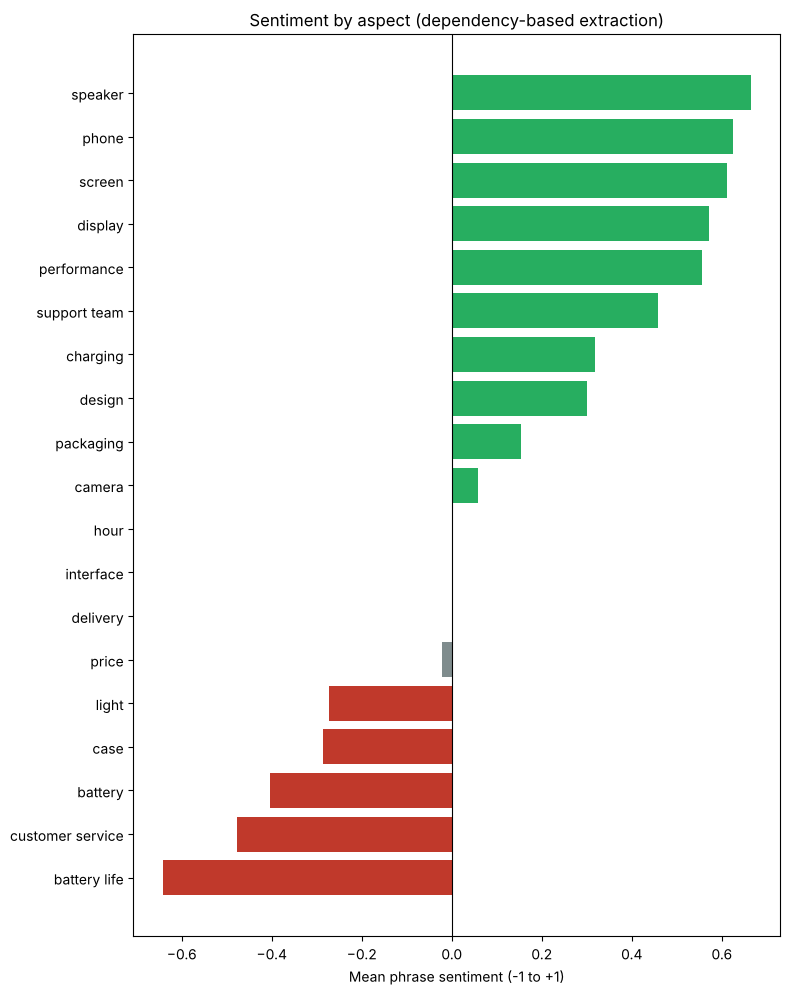

In [11]:
plot_df = agg[agg["mentions"] >= 1]
colors = ["#c0392b" if v < -0.05 else "#27ae60" if v > 0.05 else "#7f8c8d" for v in plot_df["mean_sentiment"]]

fig, ax = plt.subplots(figsize=(8, 0.45 * len(plot_df) + 1.5))
ax.barh(plot_df.index, plot_df["mean_sentiment"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Mean phrase sentiment (-1 to +1)")
ax.set_title("Sentiment by aspect (dependency-based extraction)")
plt.tight_layout()
plt.show()

### 7.2 Most frequent keywords and phrases

In [12]:
all_phrases = Counter()
for text in posts:
    all_phrases.update(keyword_phrases(nlp(text)))

pd.DataFrame(all_phrases.most_common(12), columns=["phrase", "count"])

,phrase,count
0,camera,2
1,battery,2
2,price,2
3,screen,1
4,lunch,1
5,fast charging,1
6,speaker,1
7,hour,1
8,reply,1
9,delivery,1


### 7.3 Why syntax helps: phrase-level vs. sentence-level sentiment

A sentence can mix opinions ("great screen but awful battery"), and a whole-sentence score averages them away. Here we compare both views for the same posts.

In [13]:
compare = (df.groupby("post")
             .agg(sentence_score=("sentence_score", "first"),
                  phrase_view=("opinion", lambda s: ", ".join(s)),
                  phrase_mean=("phrase_score", "mean"))
             .round(3))
compare.insert(0, "text", [posts[i] for i in compare.index])
compare

,text,sentence_score,phrase_view,phrase_mean
post,,,,
0,The camera is amazing and the screen is gorgeous.,0.832,"amazing, gorgeous",0.599
1,"The battery is not good, it dies before lunch.",-0.341,not good,-0.330
2,I love the fast charging but the price is ridiculous.,-0.166,"fast, love, ridiculous",0.092
3,"Not bad at all, the speakers are really impressive.",0.754,impressive,0.664
4,"Terrible customer service, I waited two hours for a reply.",-0.477,"terrible, waited",-0.238
5,The delivery was quick and the packaging was solid.,0.153,"quick, solid",0.076
6,This phone has a beautiful design and a smooth interface.,0.599,"beautiful, has, smooth",0.200
7,The software update ruined the battery and made the phone slow.,-0.477,ruined,-0.477
8,Honestly the camera is not great in low light.,0.133,"not great, low",-0.371


In [14]:
mixed = df.groupby("post")["phrase_label"].nunique()
mixed_posts = mixed[mixed > 1].index.tolist()
print("Posts with both positive and negative phrases:", mixed_posts)
for i in mixed_posts:
    print(f"\n[{i}] {posts[i]}")
    print("  sentence-level score:", vader.polarity_scores(posts[i])["compound"])
    print(df[df.post == i][["aspect", "opinion", "phrase_score"]].to_string(index=False))

Posts with both positive and negative phrases: [2, 4, 5, 6, 9, 11]

[2] I love the fast charging but the price is ridiculous.
  sentence-level score: -0.1655
  aspect    opinion  phrase_score
charging       fast         0.000
charging       love         0.637
   price ridiculous        -0.361

[4] Terrible customer service, I waited two hours for a reply.
  sentence-level score: -0.4767
          aspect  opinion  phrase_score
customer service terrible        -0.477
            hour   waited         0.000

[5] The delivery was quick and the packaging was solid.
  sentence-level score: 0.1531
   aspect opinion  phrase_score
 delivery   quick         0.000
packaging   solid         0.153

[6] This phone has a beautiful design and a smooth interface.
  sentence-level score: 0.5994
   aspect   opinion  phrase_score
   design beautiful         0.599
   design       has         0.000
interface    smooth         0.000

[9] I hate the flimsy case that came with it.
  sentence-level score: -0.57

## 8. Checking negation handling

The `neg` dependency is what makes *not good* come out negative and *not bad* come out positive. Checking those cases directly:

In [15]:
tests = ["The battery is good.", "The battery is not good.", "The case is bad.", "The case is not bad."]
for t in tests:
    out = [(p["aspect"], ("not " if p["negated"] else "") + p["opinion"],
            round(opinion_score(p["opinion"], p["negated"], p["boost"]), 2))
           for p in extract_pairs(nlp(t))]
    print(f"{t:28s} -> {out}")

The battery is good.         -> [('battery', 'good', 0.44)]
The battery is not good.     -> [('battery', 'not good', -0.33)]
The case is bad.             -> [('case', 'bad', -0.54)]
The case is not bad.         -> [('case', 'not bad', 0.41)]


## 9. Discussion

**What worked**

- Dependency rules connected opinions to the right aspect, so *fast* attached to charging while *ridiculous* attached to price, even in the same sentence.
- The `neg` relation fixed polarity for *not good* and *not bad*, which a bag-of-words approach gets wrong.
- Aggregating by aspect turned individual posts into a feature-level summary.

**Limitations we noticed**

- **Sarcasm.** "Great, another phone that overheats" is read as positive because *great* is the only opinion the rules find. Syntax alone cannot detect irony; this needs context or a trained model.
- **Rule coverage.** We handle four patterns. Passive voice, comparatives ("better than"), and implicit opinions ("it dies before lunch") are missed or only partly captured.
- **Lexicon sentiment.** VADER is a general-purpose lexicon. Domain slang or dialect can be scored wrongly.
- **Small, invented sample.** The posts are for demonstration; conclusions should come from real data.

**Possible extensions**

- Replace the lexicon with a pretrained sentiment model (for example a transformer from Hugging Face) while still using dependency parsing to decide *which phrase* to score.
- Add rules for passives, comparatives and clause-level contrast.
- Run on a real dataset and evaluate against hand-labelled aspects.

## 10. Conclusion

Syntactic analysis told us *where to look* (which words relate to which), and semantic analysis told us *how to feel about it* (the polarity of those words). Together they gave a more precise reading of social-media text than sentence-level scoring alone, with clear gaps that point to the next improvements.

*Prepared by Steve and Spencer.*